> **Hồ sơ nguồn của EXP-011 — LR cân bằng lớp.** `THAI-EXP-003` là mã lần chạy cũ, không phải một hướng mới. Mở `notebooks/experiments/EXP-011_LR_Balanced.ipynb` để tổng hợp theo kế hoạch chung. Giữ nguyên code training và đường dẫn nguồn để truy vết.

# THAI-EXP-003 — Logistic Regression cân bằng lớp

Người thực hiện: Thái

Ngày 16/11/2026

## Mục tiêu
Đánh giá tác động của class_weight="balanced" trên LR, đối chứng với THAI-EXP-002 trên cùng dữ liệu và cách chia fold.

## Giả thuyết trước khi chạy
Cân bằng trọng số lớp có thể giúp LR nhận diện lớp ít mẫu hơn.
Macro-F1 và Balanced Accuracy có thể tăng hoặc giảm tùy từng người.

## Thiết lập
- Hai bài toán: multiclass và binary.
- R01 kiểm tra S2; R02 chạy LOSO đủ 15 người.
- Imputer median và StandardScaler được fit trong train của từng fold.
- Chưa tuning; chỉ thay đổi class_weight="balanced" so với THAI-EXP-002.
- Độ đo: Macro-F1 và Balanced Accuracy.


In [1]:
from pathlib import Path
from copy import deepcopy
import os
import sys
import json
import hashlib
import warnings

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/wesad/models.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Không tìm thấy thư mục dự án.")
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
os.environ.setdefault("MPLCONFIGDIR", str(Path(os.environ["TEMP"]) / "wesad_matplotlib"))
import matplotlib.pyplot as plt
from IPython.display import display, Image
from wesad.data import SUBJECTS, load_feature_table
from wesad.evaluation import run_experiment
from wesad.models import build_pipeline
from wesad.utils import read_config, file_hash, fingerprint, environment

plt.switch_backend("Agg")
print("Project:", ROOT)
print("Python:", sys.executable)


Project: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection
Python: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\.venv\Scripts\python.exe


## Kiểm tra dữ liệu

In [2]:
defaults = read_config(ROOT / "configs/defaults.yaml")
FEATURES = ROOT / defaults["features"]
SCHEMA = ROOT / defaults["schema"]
assert file_hash(FEATURES) == defaults["feature_sha256"]
df, feature_columns = load_feature_table(FEATURES, SCHEMA, SUBJECTS)
assert len(df) == 6189 and len(feature_columns) == 68
print("Số cửa sổ:", len(df))
print("Số đặc trưng:", len(feature_columns))
print("Số người:", df.subject_id.nunique())
print("Giá trị thiếu:", int(df[feature_columns].isna().sum().sum()))
display(pd.crosstab(df.subject_id, df.label_original).reindex(SUBJECTS))


Số cửa sổ: 6189
Số đặc trưng: 68
Số người: 15
Giá trị thiếu: 37460


label_original,1,2,3
subject_id,,,
S2,219,113,63
S3,218,118,65
S4,222,117,65
S5,230,119,65
S6,226,121,65
S7,228,118,65
S8,224,124,64
S9,227,119,65
S10,226,135,65


## R01 — Kiểm tra trên S2

Train 14 người còn lại, test S2. Kiểm tra pipeline và đầu ra trước khi chạy đầy đủ.

In [3]:
CONFIG = deepcopy(defaults)
CONFIG.update({
    "protocol": "notebook_research_new_runs_v1",
    "experiment_id": "THAI-EXP-003",
    "group_experiment_id": "EXP-011",
    "run_no": "r01",
    "run_scope": "quick",
    "models": ["lr"],
    "tasks": ["multiclass", "binary"],
    "balance": True,
    "nested": False,
    "output_dir": "outputs/notebook_research/THAI-EXP-003/r01_quick",
    "source_paths": ["src/wesad/data.py", "src/wesad/evaluation.py",
                     "src/wesad/models.py", "src/wesad/utils.py"],
})
pipeline = build_pipeline("lr", CONFIG)
assert pipeline.named_steps["model"].class_weight == "balanced"
display(pipeline)
RUN_DIR = ROOT / CONFIG["output_dir"]
result = run_experiment(CONFIG, resume=True, outer_subjects=["S2"])
metrics = pd.read_csv(RUN_DIR / "metrics_by_subject.csv")
assert len(metrics) == 2 and set(metrics.subject_id) == {"S2"}
print("Trạng thái:", result["status"])
display(metrics)


multiclass/lr/S2: SKIP verified
binary/lr/S2: SKIP verified
Trạng thái: partial


,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True


,subject_id,task,model,n_test,macro_f1,balanced_accuracy,seconds
0,S2,multiclass,lr,395,0.458796,0.613394,0.1718
1,S2,binary,lr,395,0.414815,0.496454,0.0568


## Kiểm tra cảnh báo R01

In [4]:
def read_warnings(folder):
    rows = []
    for path in sorted((folder / "folds").glob("*/*/*/details.json")):
        detail = json.loads(path.read_text(encoding="utf-8"))
        assert set(detail["outer_train_subjects"]).isdisjoint(detail["outer_test_subjects"])
        for message in detail["warnings"]:
            rows.append({"task": path.parents[2].name,
                         "subject_id": path.parent.name, "warning": message})
    return pd.DataFrame(rows, columns=["task", "subject_id", "warning"])

warnings_r01 = read_warnings(RUN_DIR)
display(warnings_r01)
print("Số cảnh báo R01:", len(warnings_r01))


Số cảnh báo R01: 0


,task,subject_id,warning


## Nhận xét R01

- multiclass: Macro-F1 = 0.458796; Balanced Accuracy = 0.613394.
- binary: Macro-F1 = 0.414815; Balanced Accuracy = 0.496454.

Ghi nhận 0 cảnh báo trong hai fold R01. Giữ nguyên tham số để chạy đủ 15 người.

## R02 — LR cân bằng lớp đủ 15 người

Giữ nguyên thiết lập R01. Mỗi fold train trên 14 người và test người còn lại.
Không điều chỉnh tham số theo kết quả S2. Tổng cộng 30 fold cho hai bài toán.


In [5]:
CONFIG_R02 = deepcopy(CONFIG)
CONFIG_R02.update({"run_no": "r02", "run_scope": "main",
                   "output_dir": "outputs/notebook_research/THAI-EXP-003/r02_main"})
RUN_DIR_R02 = ROOT / CONFIG_R02["output_dir"]
result_r02 = run_experiment(CONFIG_R02, resume=True, outer_subjects=None)
assert result_r02["status"] == "complete"
metrics_r02 = pd.read_csv(RUN_DIR_R02 / "metrics_by_subject.csv")
assert len(metrics_r02) == 30
assert not metrics_r02.duplicated(["task", "model", "subject_id"]).any()
for task in ["binary", "multiclass"]:
    assert set(metrics_r02.loc[metrics_r02.task.eq(task), "subject_id"]) == set(SUBJECTS)
print("PASS: đủ 30 fold, không trùng kết quả.")
display(metrics_r02)
summary_r02 = metrics_r02.groupby("task")[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
display(summary_r02)
warnings_r02 = read_warnings(RUN_DIR_R02)
display(warnings_r02)
print("Số cảnh báo R02:", len(warnings_r02))


multiclass/lr/S10: SKIP verified
multiclass/lr/S11: SKIP verified
multiclass/lr/S13: SKIP verified
multiclass/lr/S14: SKIP verified
multiclass/lr/S15: SKIP verified
multiclass/lr/S16: SKIP verified
multiclass/lr/S17: SKIP verified
multiclass/lr/S2: SKIP verified
multiclass/lr/S3: SKIP verified
multiclass/lr/S4: SKIP verified
multiclass/lr/S5: SKIP verified
multiclass/lr/S6: SKIP verified
multiclass/lr/S7: SKIP verified
multiclass/lr/S8: SKIP verified
multiclass/lr/S9: SKIP verified
binary/lr/S10: SKIP verified
binary/lr/S11: SKIP verified
binary/lr/S13: SKIP verified
binary/lr/S14: SKIP verified
binary/lr/S15: SKIP verified
binary/lr/S16: SKIP verified
binary/lr/S17: SKIP verified
binary/lr/S2: SKIP verified
binary/lr/S3: SKIP verified
binary/lr/S4: SKIP verified
binary/lr/S5: SKIP verified
binary/lr/S6: SKIP verified
binary/lr/S7: SKIP verified
binary/lr/S8: SKIP verified
binary/lr/S9: SKIP verified
PASS: đủ 30 fold, không trùng kết quả.
Số cảnh báo R02: 0


,subject_id,task,model,n_test,macro_f1,balanced_accuracy,seconds
0,S10,multiclass,lr,426,0.270507,0.367257,0.0927
1,S11,multiclass,lr,417,0.551448,0.603570,0.1025
2,S13,multiclass,lr,417,0.592222,0.635360,0.1048
3,S14,multiclass,lr,410,0.411750,0.531273,0.1103
4,S15,multiclass,lr,418,0.689308,0.756199,0.1067
5,S16,multiclass,lr,415,0.336539,0.373156,0.0998
6,S17,multiclass,lr,426,0.673234,0.685758,0.1109
7,S2,multiclass,lr,395,0.458796,0.613394,0.1068
8,S3,multiclass,lr,401,0.681823,0.645103,0.1024
9,S4,multiclass,lr,404,0.765223,0.748718,0.1137


macro_f1           balanced_accuracy          
                mean       std              mean       std
task                                                      
binary      0.810281  0.186783          0.831881  0.169527
multiclass  0.585266  0.162972          0.630372  0.142832

,task,subject_id,warning


## So sánh với LR mặc định

So sánh theo cùng người test và cùng bài toán.

In [6]:
REFERENCE_DIR = ROOT / "outputs/notebook_research/THAI-EXP-002/r02_main"
reference_manifest = json.loads((REFERENCE_DIR / "config.json").read_text(encoding="utf-8"))
lr_manifest = json.loads((RUN_DIR_R02 / "config.json").read_text(encoding="utf-8"))
assert reference_manifest["data_sha256"] == lr_manifest["data_sha256"]
assert reference_manifest["code_sha256"] == lr_manifest["code_sha256"]
assert reference_manifest["environment"] == lr_manifest["environment"]
for key in ["feature_version", "feature_sha256", "seed", "sensor_set", "normalization", "nested", "model_params", "tasks", "models", "expected_subjects"]:
    assert reference_manifest["settings"].get(key) == lr_manifest["settings"].get(key), key
assert reference_manifest["settings"]["balance"] is False
assert lr_manifest["settings"]["balance"] is True
reference_metrics = pd.read_csv(REFERENCE_DIR / "metrics_by_subject.csv")
comparison = metrics_r02.merge(reference_metrics, on=["task", "subject_id"],
                              suffixes=("_lr", "_reference"), validate="one_to_one")
assert len(comparison) == 30
assert comparison.n_test_lr.eq(comparison.n_test_reference).all()
for metric in ["macro_f1", "balanced_accuracy"]:
    comparison[metric + "_delta"] = comparison[metric + "_lr"] - comparison[metric + "_reference"]
display(comparison)
display(comparison.groupby("task")[["macro_f1_delta", "balanced_accuracy_delta"]].agg(["mean", "std"]))
for task, part in comparison.groupby("task"):
    print(task, "| tăng:", int((part.macro_f1_delta > 1e-12).sum()),
          "| giảm:", int((part.macro_f1_delta < -1e-12).sum()),
          "| gần như bằng:", int((part.macro_f1_delta.abs() <= 1e-12).sum()))
comparison.to_csv(RUN_DIR_R02 / "comparison_by_subject.csv", index=False)


binary | tăng: 4 | giảm: 6 | gần như bằng: 5
multiclass | tăng: 7 | giảm: 8 | gần như bằng: 0


,subject_id,task,model_lr,n_test_lr,macro_f1_lr,balanced_accuracy_lr,seconds_lr,model_reference,n_test_reference,macro_f1_reference,balanced_accuracy_reference,seconds_reference,macro_f1_delta,balanced_accuracy_delta
0,S10,multiclass,lr,426,0.270507,0.367257,0.0927,lr,426,0.290313,0.379056,0.5834,-0.019806,-0.011799
1,S11,multiclass,lr,417,0.551448,0.603570,0.1025,lr,417,0.593778,0.630667,0.8793,-0.042330,-0.027097
2,S13,multiclass,lr,417,0.592222,0.635360,0.1048,lr,417,0.582100,0.619231,0.6830,0.010122,0.016129
3,S14,multiclass,lr,410,0.411750,0.531273,0.1103,lr,410,0.469508,0.559466,0.7089,-0.057757,-0.028193
4,S15,multiclass,lr,418,0.689308,0.756199,0.1067,lr,418,0.707997,0.770603,0.5803,-0.018689,-0.014404
5,S16,multiclass,lr,415,0.336539,0.373156,0.0998,lr,415,0.363506,0.390855,0.7959,-0.026967,-0.017699
6,S17,multiclass,lr,426,0.673234,0.685758,0.1109,lr,426,0.637518,0.667492,0.8430,0.035716,0.018266
7,S2,multiclass,lr,395,0.458796,0.613394,0.1068,lr,395,0.466127,0.621005,0.6737,-0.007331,-0.007610
8,S3,multiclass,lr,401,0.681823,0.645103,0.1024,lr,401,0.661182,0.622287,0.5461,0.020641,0.022816
9,S4,multiclass,lr,404,0.765223,0.748718,0.1137,lr,404,0.701802,0.707692,0.6586,0.063422,0.041026


macro_f1_delta           balanced_accuracy_delta          
                     mean       std                    mean       std
task                                                                 
binary           0.000012  0.022668                0.001519  0.016237
multiclass      -0.004125  0.034515               -0.001099  0.022373

## Biểu đồ kết quả


Ảnh được lưu tại: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\outputs\notebook_research\THAI-EXP-003\r02_main\figures
Cột sai số ở bảng tổng hợp là độ lệch chuẩn giữa các người.
Confusion matrix gộp cửa sổ; bảng tổng hợp tính trung bình theo người.


macro_f1           balanced_accuracy          
                mean       std              mean       std
task                                                      
binary      0.810281  0.186783          0.831881  0.169527
multiclass  0.585266  0.162972          0.630372  0.142832

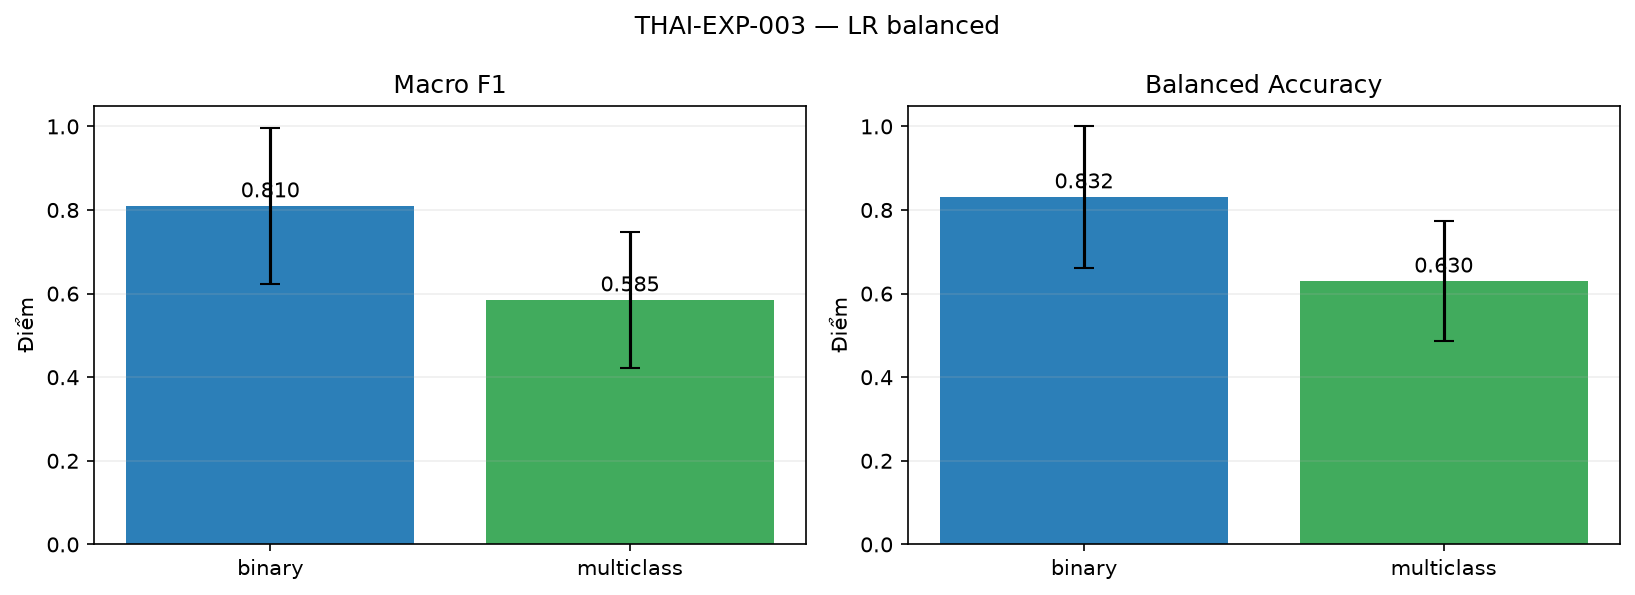

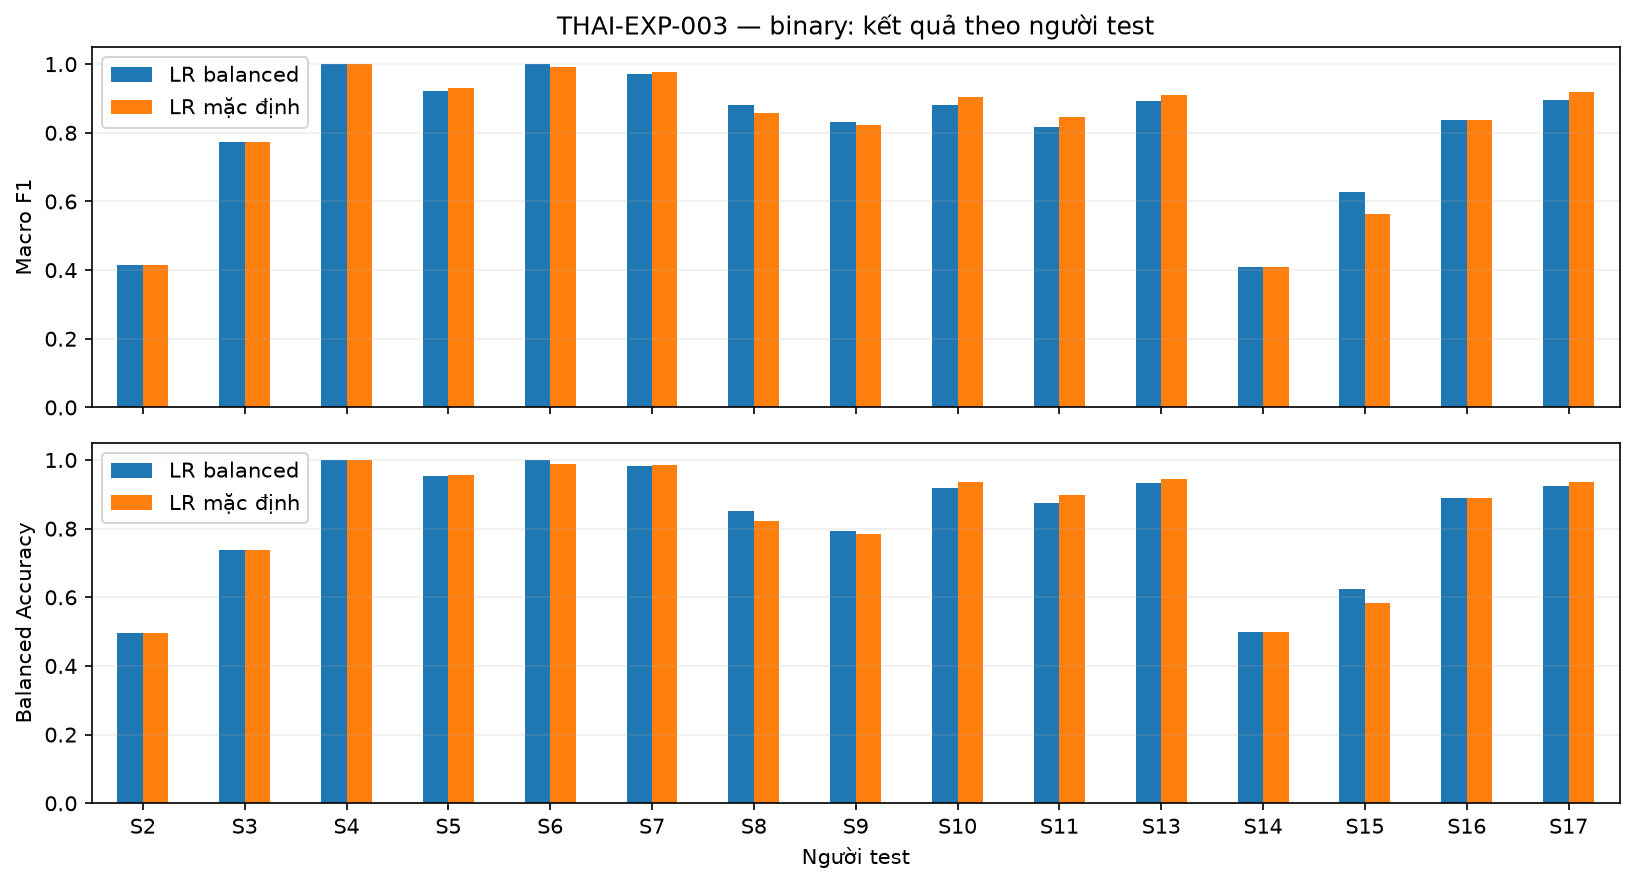

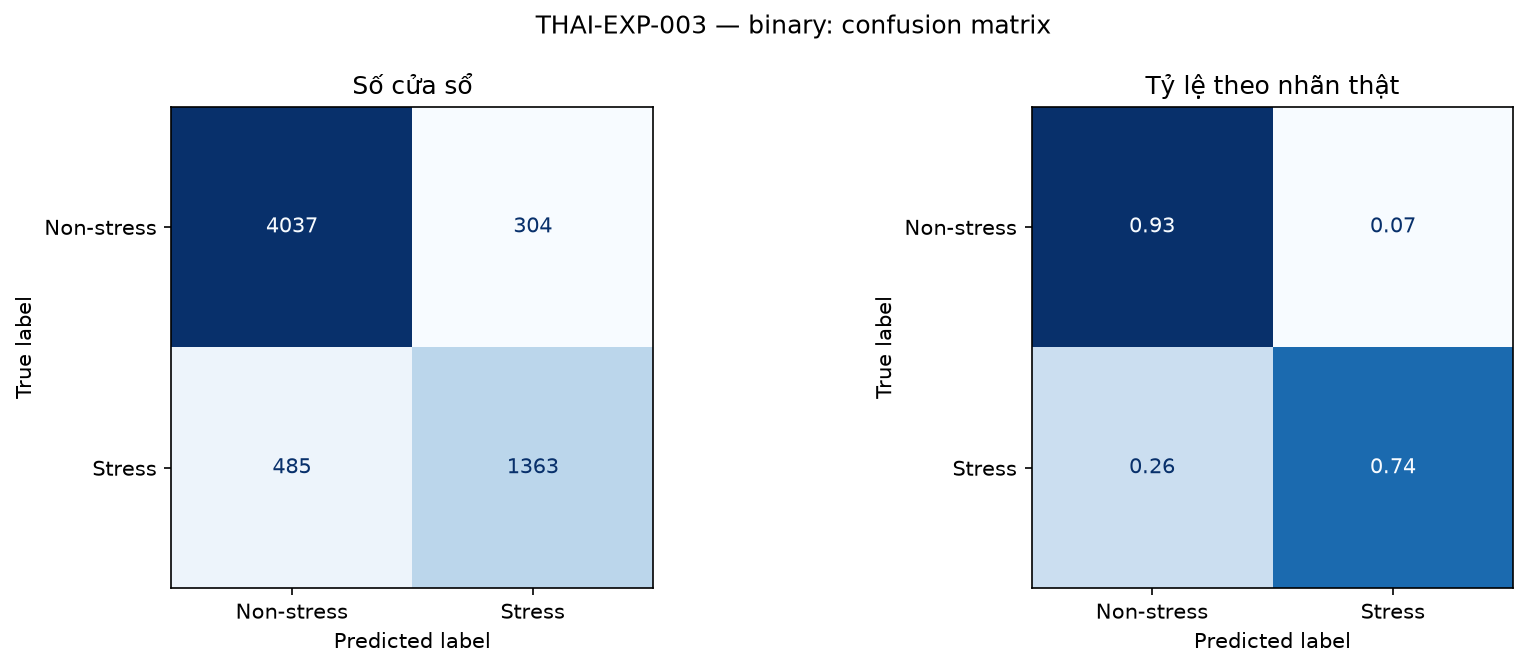

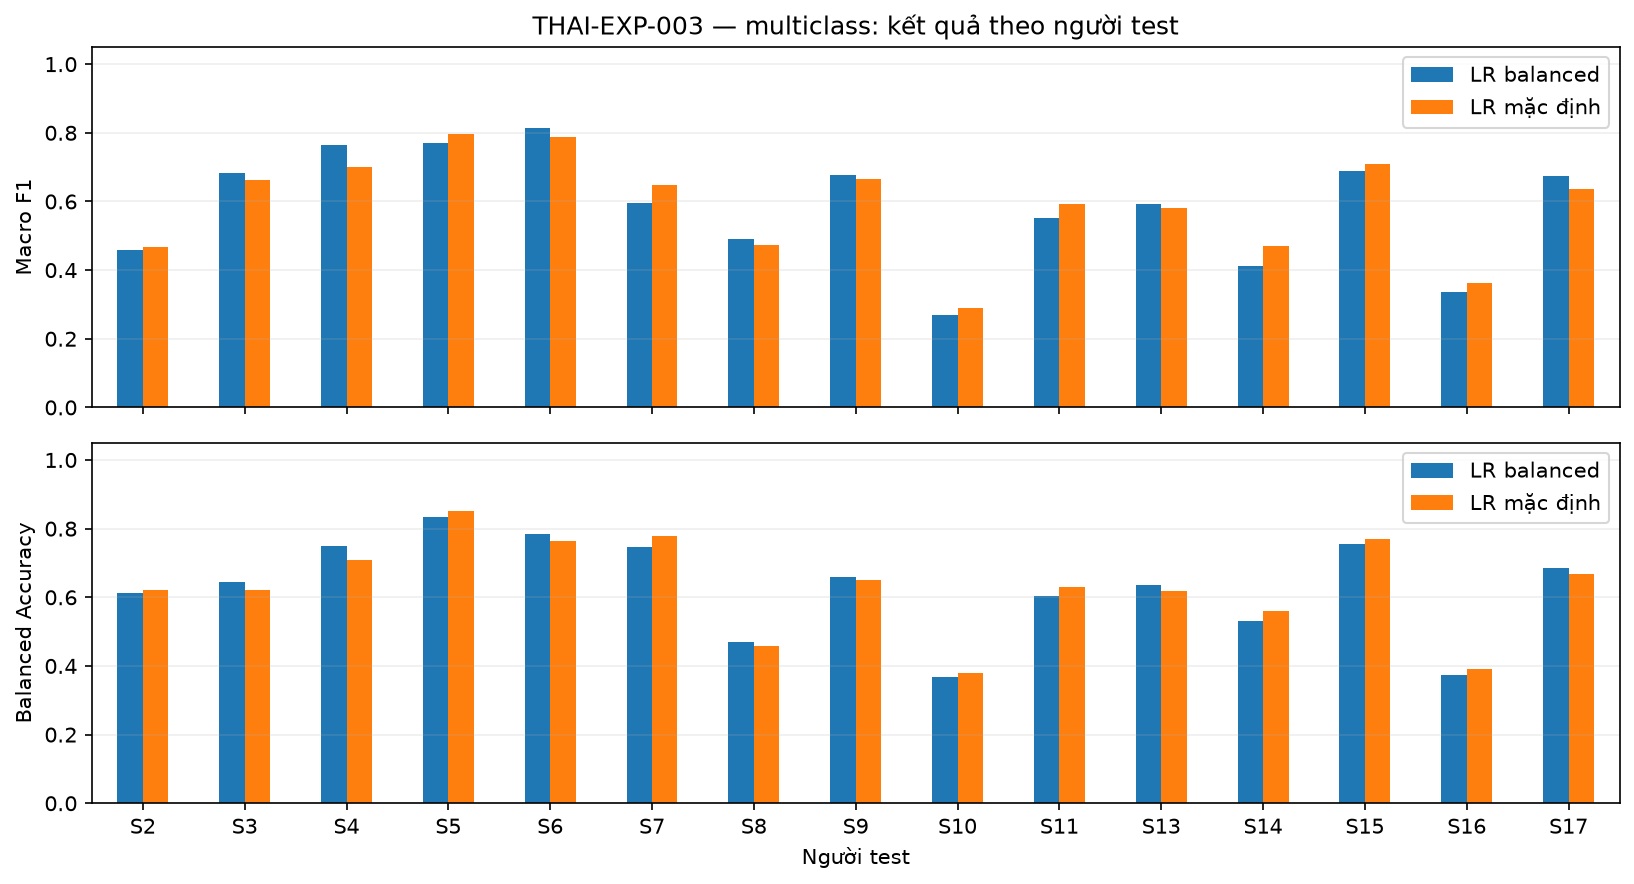

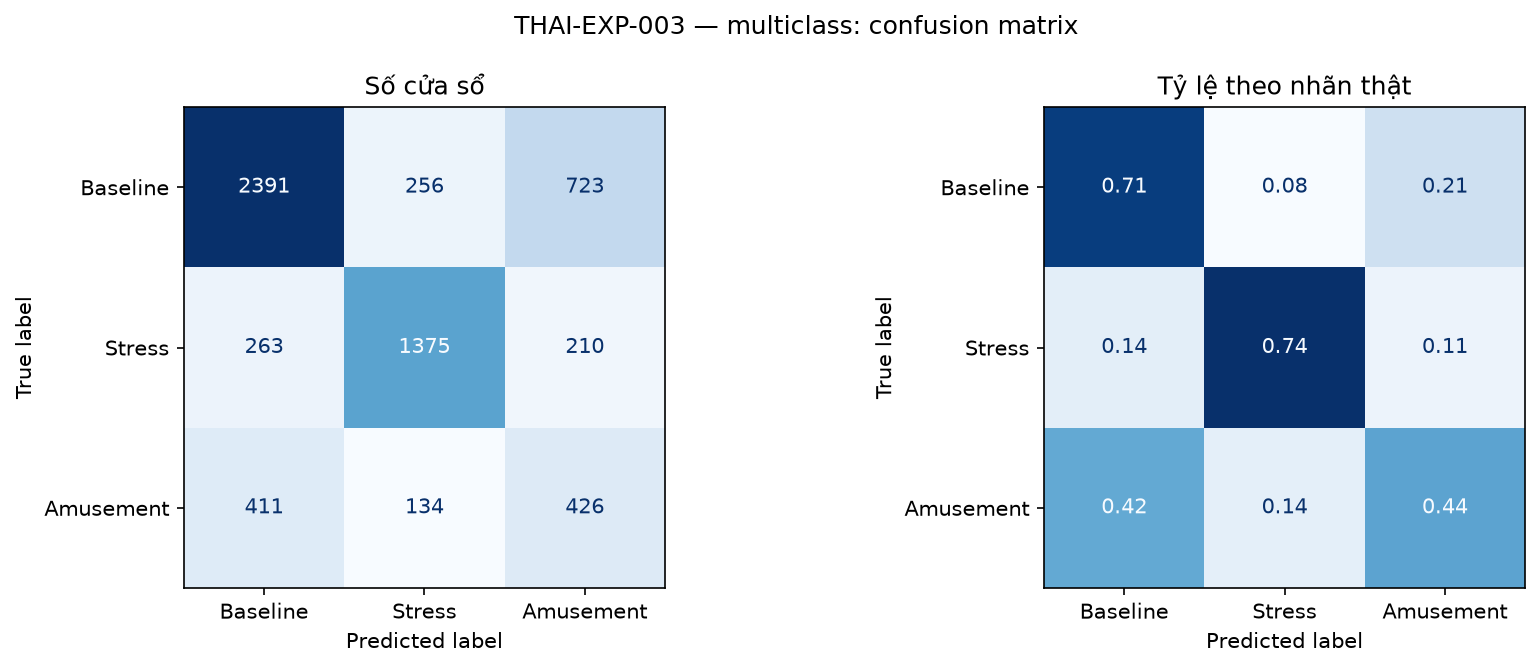

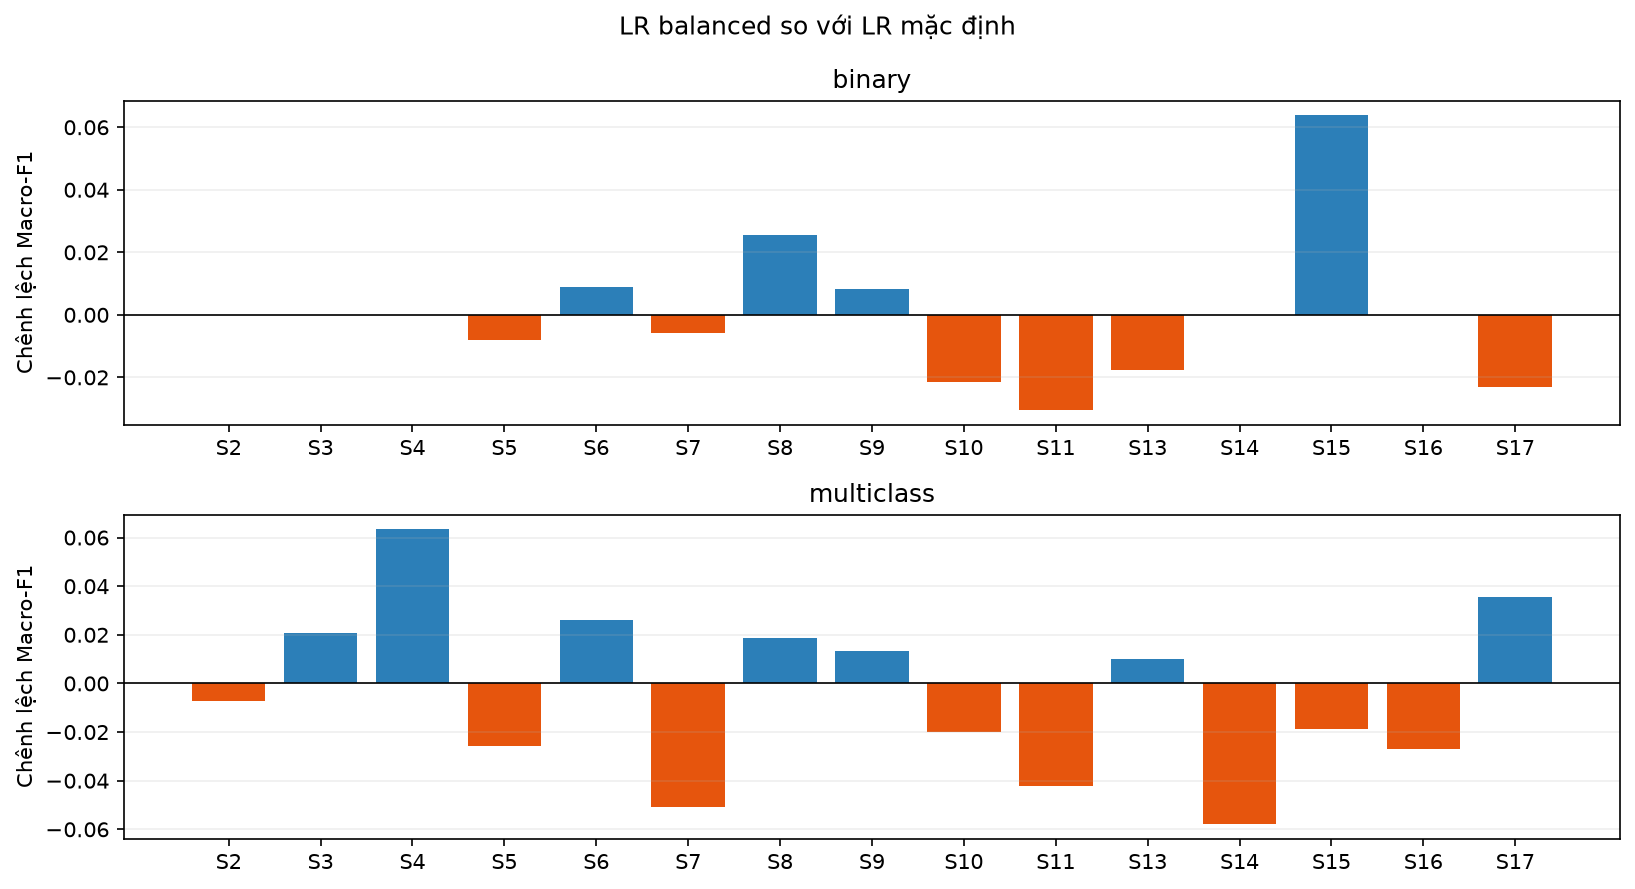

In [7]:
from pathlib import Path
import os
os.environ.setdefault("MPLCONFIGDIR", str(Path(os.environ["TEMP"]) / "wesad_matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/wesad/models.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Hãy mở notebook trong thư mục dự án.")

RUN_DIR_VIS = ROOT / "outputs/notebook_research/THAI-EXP-003/r02_main"
REFERENCE_VIS = ROOT / "outputs/notebook_research/THAI-EXP-002/r02_main"
MODEL_LABEL = "LR balanced"
REFERENCE_LABEL = "LR mặc định"
FIGURES_VIS = RUN_DIR_VIS / "figures"

for name in ["metrics_by_subject.csv", "predictions.csv"]:
    if not (RUN_DIR_VIS / name).is_file():
        raise FileNotFoundError(f"Thiếu kết quả: {RUN_DIR_VIS / name}")

metrics_vis = pd.read_csv(RUN_DIR_VIS / "metrics_by_subject.csv")
predictions_vis = pd.read_csv(RUN_DIR_VIS / "predictions.csv")
assert not metrics_vis.duplicated(["task", "model", "subject_id"]).any()
assert not predictions_vis.duplicated(["task", "model", "subject_id", "window_id"]).any()
assert metrics_vis.model.nunique() == 1
reference_vis = None
if REFERENCE_VIS is not None:
    reference_vis = pd.read_csv(REFERENCE_VIS / "metrics_by_subject.csv")
    paired_vis = metrics_vis.merge(reference_vis, on=["task", "subject_id"],
                                   suffixes=("_current", "_reference"), validate="one_to_one")
    assert len(paired_vis) == len(metrics_vis)
    assert paired_vis.n_test_current.eq(paired_vis.n_test_reference).all()

FIGURES_VIS.mkdir(parents=True, exist_ok=True)
plt.switch_backend("Agg")
def show_figure(fig, filename):
    fig.tight_layout()
    target = FIGURES_VIS / filename
    fig.savefig(target, dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(target)))

summary_vis = metrics_vis.groupby("task")[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
display(summary_vis)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["macro_f1", "balanced_accuracy"]):
    means = summary_vis[(metric, "mean")]
    deviations = summary_vis[(metric, "std")].fillna(0)
    ax.bar(means.index, means, yerr=deviations, capsize=5, color=["#2c7fb8", "#41ab5d"][:len(means)])
    ax.set(title=metric.replace("_", " ").title(), ylim=(0, 1.05), ylabel="Điểm")
    ax.grid(axis="y", alpha=0.2)
    for x, mean in enumerate(means):
        ax.text(x, mean + 0.02, f"{mean:.3f}", ha="center")
fig.suptitle(f"THAI-EXP-003 — {MODEL_LABEL}")
show_figure(fig, "summary_metrics.png")

for task in ["binary", "multiclass"]:
    part = metrics_vis.loc[metrics_vis.task.eq(task)].copy()
    if part.empty:
        continue
    subjects = sorted(part.subject_id.unique(), key=lambda s: int(s[1:]))
    part = part.set_index("subject_id").reindex(subjects)
    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    for ax, metric in zip(axes, ["macro_f1", "balanced_accuracy"]):
        scores = pd.DataFrame({MODEL_LABEL: part[metric]})
        if reference_vis is not None:
            ref = reference_vis.loc[reference_vis.task.eq(task)].set_index("subject_id").reindex(subjects)
            scores[REFERENCE_LABEL] = ref[metric]
        scores.plot.bar(ax=ax, ylim=(0, 1.05), rot=0)
        ax.set_ylabel(metric.replace("_", " ").title())
        ax.grid(axis="y", alpha=0.2)
    axes[0].set_title(f"THAI-EXP-003 — {task}: kết quả theo người test")
    axes[1].set_xlabel("Người test")
    show_figure(fig, f"{task}_subject_metrics.png")

    macro_scores = pd.DataFrame({MODEL_LABEL: part["macro_f1"]})
    if reference_vis is not None:
        macro_scores[REFERENCE_LABEL] = ref["macro_f1"]
    ax_macro = macro_scores.plot.bar(figsize=(10, 4), ylim=(0, 1.05), rot=0)
    ax_macro.set(title=f"THAI-EXP-003 — {task}", ylabel="Macro-F1", xlabel="Người test")
    ax_macro.figure.tight_layout()
    ax_macro.figure.savefig(FIGURES_VIS / f"{task}_macro_f1.png", dpi=150)
    plt.close(ax_macro.figure)


    pred = predictions_vis.loc[predictions_vis.task.eq(task)]
    assert len(pred) == int(part.n_test.sum())
    labels = [0, 1] if task == "binary" else [1, 2, 3]
    names = ["Non-stress", "Stress"] if task == "binary" else ["Baseline", "Stress", "Amusement"]
    cm = confusion_matrix(pred.y_true, pred.y_pred, labels=labels)
    row_sums = cm.sum(axis=1, keepdims=True)
    normalized = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
    ConfusionMatrixDisplay(normalized, display_labels=names).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
    axes[0].set_title("Số cửa sổ")
    axes[1].set_title("Tỷ lệ theo nhãn thật")
    fig.suptitle(f"THAI-EXP-003 — {task}: confusion matrix")
    show_figure(fig, f"{task}_confusion_matrix.png")

if reference_vis is not None:
    fig, axes = plt.subplots(2, 1, figsize=(11, 6))
    for ax, task in zip(axes, ["binary", "multiclass"]):
        part = paired_vis.loc[paired_vis.task.eq(task)].copy()
        part["subject_number"] = part.subject_id.str[1:].astype(int)
        part = part.sort_values("subject_number")
        delta = part.macro_f1_current - part.macro_f1_reference
        ax.bar(part.subject_id, delta, color=["#2c7fb8" if d >= 0 else "#e6550d" for d in delta])
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set(title=task, ylabel="Chênh lệch Macro-F1")
        ax.grid(axis="y", alpha=0.2)
    fig.suptitle(f"{MODEL_LABEL} so với {REFERENCE_LABEL}")
    show_figure(fig, "comparison_delta_macro_f1.png")

print("Ảnh được lưu tại:", FIGURES_VIS)
if metrics_vis.subject_id.nunique() == 1:
    print("Lượt kiểm tra một người; chưa dùng để kết luận cho đủ 15 người.")
else:
    print("Cột sai số ở bảng tổng hợp là độ lệch chuẩn giữa các người.")
print("Confusion matrix gộp cửa sổ; bảng tổng hợp tính trung bình theo người.")


In [8]:
for task, part in metrics_r02.groupby("task"):
    print(task)
    for metric in ["macro_f1", "balanced_accuracy"]:
        print(f"{metric}: {part[metric].mean():.6f} ± {part[metric].std():.6f}")
    best = part.loc[part.macro_f1.idxmax()]
    worst = part.loc[part.macro_f1.idxmin()]
    print(f"Macro-F1 cao nhất: {best.subject_id} ({best.macro_f1:.6f})")
    print(f"Macro-F1 thấp nhất: {worst.subject_id} ({worst.macro_f1:.6f})")


binary
macro_f1: 0.810281 ± 0.186783
balanced_accuracy: 0.831881 ± 0.169527
Macro-F1 cao nhất: S4 (1.000000)
Macro-F1 thấp nhất: S14 (0.409222)
multiclass
macro_f1: 0.585266 ± 0.162972
balanced_accuracy: 0.630372 ± 0.142832
Macro-F1 cao nhất: S6 (0.812569)
Macro-F1 thấp nhất: S10 (0.270507)


## Kết quả và nhận xét R02

Đã hoàn thành LOSO 15 người cho hai bài toán, tổng cộng 30 fold.

- binary: Macro-F1 = 0.810281 ± 0.186783; Balanced Accuracy = 0.831881 ± 0.169527.
  Macro-F1 cao nhất ở S4 (1.000000), thấp nhất ở S14 (0.409222).
  So với LR mặc định: Macro-F1 trung bình thay đổi +0.000012; tăng ở 4 người, giảm ở 6 người.
- multiclass: Macro-F1 = 0.585266 ± 0.162972; Balanced Accuracy = 0.630372 ± 0.142832.
  Macro-F1 cao nhất ở S6 (0.812569), thấp nhất ở S10 (0.270507).
  So với LR mặc định: Macro-F1 trung bình thay đổi -0.004125; tăng ở 7 người, giảm ở 8 người.

Ghi nhận 0 cảnh báo trong R02.
Điểm trung bình và độ lệch chuẩn được tính theo người, mỗi người có trọng số bằng nhau.
Confusion matrix gộp các cửa sổ dự đoán ngoài mẫu nên có trọng số khác bảng trung bình theo người.

Macro-F1 binary gần như không đổi (+0.000012), trong khi multiclass giảm 0.004125. Cân bằng lớp chưa cho thấy cải thiện rõ rệt trong thiết lập này. Chưa kiểm định ý nghĩa thống kê của chênh lệch. Không chọn tham số dựa trên điểm outer test.

## Giới hạn

Chưa tuning lại mô hình cân bằng lớp và chưa kiểm định ý nghĩa thống kê. Kết quả trên WESAD chưa chứng minh hiệu quả ngoài thực tế.

## Quyết định tiếp theo

Thực hiện THAI-EXP-004 với feature selection trong pipeline train. Giữ THAI-EXP-002 làm đối chứng; nếu chọn số đặc trưng thì dùng inner GroupKFold, không dùng outer test để chọn.

## So sánh train và test — R02

Kết quả đủ 15 người, tính theo từng fold LOSO. Điểm train được tính trên tập đã dùng để fit.
Code và bảng tổng hợp: [notebook so sánh train–test](../04_evaluation/Thai_train_test_comparison.ipynb).

### Binary

![Train–test binary](../../experiments/04_evaluation/THAI_Train_Test_Comparison/figures/THAI-EXP-003_binary_train_test.png)

### Multiclass

![Train–test multiclass](../../experiments/04_evaluation/THAI_Train_Test_Comparison/figures/THAI-EXP-003_multiclass_train_test.png)
